In [105]:
print("My HanuAI project is working!")


My HanuAI project is working!


In [2]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")
print("Total reviews collected:", len(df))

Total reviews collected: 40


In [106]:

# HanuAI ML Assessment - Task 1
# Import libraries for review analysis and visualization.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Create a folder for our output files.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Initialize the sentiment analyzer.
analyzer = SentimentIntensityAnalyzer()

print("All libraries loaded successfully!")
print("Output folder:", OUTPUT_DIR.resolve())


All libraries loaded successfully!
Output folder: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs


In [3]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0041",
    "title": "Don't trust Gadget Source",
    "review_text": "Purchased a refurbished iPhone 14 from best buy and their trusted marketplace seller Gadget Source. Listed as \"excellent\" condition, (not \"good\" or \"fair\"), this phone came with very noticeable fading around the edges of the phone. Most likely water damage or the screen detaching. When asking for a return, Gadget Source customer service basically told me too bad, you get what you get. Extremely disappointed with Gadget Source and Best Buy for trusting this seller. I have bought refurbished phones in the past from other sellers that were honest with their description so beware of trusting Gadget Source.",
    "date": "2026-02-19",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Ry"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 41


In [107]:

# Create sample data to test our analysis.
# Replace these examples with authorized real review data later.

reviews = pd.DataFrame([
    {
        "primary_key": "TEST001",
        "title": "Excellent product",
        "review_text": "This product works perfectly and is very easy to use.",
        "date": "2026-09-15",
        "rating": 5,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 1"
    },
    {
        "primary_key": "TEST002",
        "title": "Average quality",
        "review_text": "The product is okay, but the quality could be better.",
        "date": "2026-09-16",
        "rating": 3,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 2"
    },
    {
        "primary_key": "TEST003",
        "title": "Very disappointing",
        "review_text": "It stopped working quickly and I am very unhappy.",
        "date": "2026-09-17",
        "rating": 1,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 3"
    }
])

print("Number of sample reviews:", len(reviews))
reviews


Number of sample reviews: 3


,primary_key,title,review_text,date,rating,source,reviewer_name
0,TEST001,Excellent product,This product works perfectly and is very easy ...,2026-09-15,5,Illustrative test data,Test Reviewer 1
1,TEST002,Average quality,"The product is okay, but the quality could be ...",2026-09-16,3,Illustrative test data,Test Reviewer 2
2,TEST003,Very disappointing,It stopped working quickly and I am very unhappy.,2026-09-17,1,Illustrative test data,Test Reviewer 3


In [4]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0042",
    "title": "Apple iPhone 14 will be a surprise Christmas gift!",
    "review_text": "Since it's not Christmas yet, I haven't seen the final result of *happy dancing* and *squealing*, but I can tell you that this purchase from \"Smart Orange\", through Best Buy's Market Place, the ask-a-question communication, and the speed of arrival ....well, it's all been just Excellent!! The iPhone looks perfect and I'm expecting the \"youngin\" will find this midnight coloured, refurbished phone to be just perfect for them!! Thank you very much \"Smart Orange\" for this great simple and direct, buy and sell experience. Merry Christmas and to you for a great New Year 2026!! Kind Regards",
    "date": "2025-12-21",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by M-Loe"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 42


In [108]:

# Standardize text, dates, and ratings.
# Remove duplicate review IDs and invalid ratings.

reviews["title"] = reviews["title"].fillna("").astype(str).str.strip()
reviews["review_text"] = reviews["review_text"].fillna("").astype(str).str.strip()

reviews["date"] = pd.to_datetime(
    reviews["date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

reviews["rating"] = pd.to_numeric(
    reviews["rating"], errors="coerce"
)

reviews = reviews.drop_duplicates(subset=["primary_key"])

reviews = reviews[
    reviews["review_text"].ne("")
    & reviews["rating"].between(1, 5)
].copy()

print("Valid reviews:", len(reviews))
print("Missing values per column:")
print(reviews.isna().sum())


Valid reviews: 3
Missing values per column:
primary_key      0
title            0
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64


In [5]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0042",
    "title": "Scratched up & Poor battery health",
    "review_text": "Screen is very noticeably scratched up on and battery health is 86%, which will need replacing. Very disappointed.",
    "date": "2025-10-16",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by n"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 42


In [109]:

# VADER gives each review a compound sentiment score.
# Scores >= 0.05 are positive; <= -0.05 are negative.
# Scores between these thresholds are neutral.

def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"


reviews["sentiment"] = reviews["review_text"].apply(classify_sentiment)

reviews["sentiment_score"] = reviews["review_text"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

reviews[[
    "primary_key", "title", "review_text",
    "rating", "sentiment", "sentiment_score"
]]


,primary_key,title,review_text,rating,sentiment,sentiment_score
0,TEST001,Excellent product,This product works perfectly and is very easy ...,5,Positive,0.8122
1,TEST002,Average quality,"The product is okay, but the quality could be ...",3,Positive,0.6486
2,TEST003,Very disappointing,It stopped working quickly and I am very unhappy.,1,Negative,-0.6115


In [6]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0043",
    "title": "Iphone 14 128gb from Techachi",
    "review_text": "Communication was on point, received a responses in 1 business day. Delivery speed was reasonable got it in a week. Phone condition in terms of physicality, it only has minor scratches which isn’t visible to the naked eye. Plus the screen display is not a genuine apple product, it says “Display Not Recognized”. Battery health was a bit disappointing it’s at 84% stating that its in excellent condition and the seller telling me the requirement for best buy product is 85% and above. Above all everything else is working perfectly fine",
    "date": "2026-07-28",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sam"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 43


In [110]:

# Export the current test results to CSV and Excel.
# These files contain sample data until real authorized reviews are loaded.

csv_path = OUTPUT_DIR / "product_reviews_sentiment.csv"
excel_path = OUTPUT_DIR / "product_reviews_sentiment.xlsx"

reviews.to_csv(csv_path, index=False, encoding="utf-8-sig")
reviews.to_excel(excel_path, index=False)

print("CSV saved to:", csv_path.resolve())
print("Excel saved to:", excel_path.resolve())


CSV saved to: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.csv
Excel saved to: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.xlsx


In [7]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0044",
    "title": "Very bad experience",
    "review_text": "I’ve bought a refurbished Iphone from BestBuy marketplace that was labeled as in « excellent condition ». After 2 weeks the phone started glitching and closing for no reason. I’ve been trying to getting it fixed and reimburse for a month now, but i feel like i got completely scammed. Never buying there again",
    "date": "2026-09-16",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Nick"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 44


In [1]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")
print("Total reviews collected:", len(df))

Total reviews collected: 40


In [8]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0045",
    "title": "Good for used",
    "review_text": "Took a long time to arrive, shipped after a week opposed to the supposed two days. Battery health was underwhelming at 85%, was hoping for a bit higher after reading other reviews. Other than that, good purchase.",
    "date": "2025-07-31",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sam"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 45


In [111]:

# HanuAI Task 1: Create sample product reviews.
# These are illustrative examples, NOT actual Best Buy reviews.

reviews = pd.DataFrame([
    {
        "primary_key": "TEST001",
        "title": "Excellent product",
        "review_text": "This product works perfectly and is very easy to use.",
        "date": "2026-09-15",
        "rating": 5,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 1"
    },
    {
        "primary_key": "TEST002",
        "title": "Average quality",
        "review_text": "The product is okay, but the quality could be better.",
        "date": "2026-09-16",
        "rating": 3,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 2"
    },
    {
        "primary_key": "TEST003",
        "title": "Very disappointing",
        "review_text": "It stopped working quickly and I am very unhappy.",
        "date": "2026-09-17",
        "rating": 1,
        "source": "Illustrative test data",
        "reviewer_name": "Test Reviewer 3"
    }
])

print("Number of sample reviews:", len(reviews))
reviews


Number of sample reviews: 3


,primary_key,title,review_text,date,rating,source,reviewer_name
0,TEST001,Excellent product,This product works perfectly and is very easy ...,2026-09-15,5,Illustrative test data,Test Reviewer 1
1,TEST002,Average quality,"The product is okay, but the quality could be ...",2026-09-16,3,Illustrative test data,Test Reviewer 2
2,TEST003,Very disappointing,It stopped working quickly and I am very unhappy.,2026-09-17,1,Illustrative test data,Test Reviewer 3


In [9]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0046",
    "title": "Pretty good",
    "review_text": "The phone was clean and in good condition. After turning it on I realized that the language had been left in French. It was a bit of a challenge changing it back to English since I don’t speak much French. Putting the phones together did not result in a complete download and most of the customization I had to do by hand. This took a long time. The phone is smaller than I thought it would be. The phone arrived a day after promised. But there had been a snow storm. Un",
    "date": "2026-01-19",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by MCS"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 46


In [112]:

# Step 1: Clean the review data

# Remove extra spaces and handle missing text
reviews["title"] = reviews["title"].fillna("").astype(str).str.strip()
reviews["review_text"] = reviews["review_text"].fillna("").astype(str).str.strip()

# Convert dates to YYYY-MM-DD format
reviews["date"] = pd.to_datetime(
    reviews["date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

# Make sure ratings are numeric
reviews["rating"] = pd.to_numeric(
    reviews["rating"], errors="coerce"
)

# Remove duplicate review IDs
reviews = reviews.drop_duplicates(subset=["primary_key"])

# Keep reviews with text and ratings from 1 to 5
reviews = reviews[
    reviews["review_text"].ne("")
    & reviews["rating"].between(1, 5)
].copy()

print("Valid reviews:", len(reviews))
print("\nMissing values in each column:")
print(reviews.isna().sum())

reviews


Valid reviews: 3

Missing values in each column:
primary_key      0
title            0
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64


,primary_key,title,review_text,date,rating,source,reviewer_name
0,TEST001,Excellent product,This product works perfectly and is very easy ...,2026-09-15,5,Illustrative test data,Test Reviewer 1
1,TEST002,Average quality,"The product is okay, but the quality could be ...",2026-09-16,3,Illustrative test data,Test Reviewer 2
2,TEST003,Very disappointing,It stopped working quickly and I am very unhappy.,2026-09-17,1,Illustrative test data,Test Reviewer 3


In [10]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0047",
    "title": "Renewed I Phone",
    "review_text": "Up on receipt I was disappointed to note that although this item was described as Excellent it was at 83% battery status. Since I was upgrading from a iPhone SE I assumed the migration would be easy. Once the SIM card was transferred my connection to my provider be came a problem. No connection or lost connection. 2 phone calls, 2 visits to a Vidéotron shop …re insert nano sim card, new SIM card..the conclusion possible defective SIM card tray or connection.Finally connected with a E SIM. 12 hours lost time, phone calls. Conclusion ..defective sim card tray or connection. Learned that my purchase was an Asian or Japanese refurbished product. Nothing in the box sent me had any info. As to who to call,WHO IS SELLER no information as to Warranty…..IF ANYBODY READS THIS WHERE IS THE INFO. ONE ONE YEAR WARRANTY STAED IN THE AD",
    "date": "2026-07-14",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Paul M"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 47


In [113]:

# Step 2: Analyze review sentiment

def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


# Classify every review
reviews["sentiment"] = reviews["review_text"].apply(
    classify_sentiment
)

# Save the sentiment score
reviews["sentiment_score"] = reviews["review_text"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

# Display the results
reviews[
    ["primary_key", "title", "rating", "sentiment", "sentiment_score"]
]


,primary_key,title,rating,sentiment,sentiment_score
0,TEST001,Excellent product,5,Positive,0.8122
1,TEST002,Average quality,3,Positive,0.6486
2,TEST003,Very disappointing,1,Negative,-0.6115


In [11]:
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("data/bestbuy_reviews.csv")

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        sentiment = "Positive"
    elif score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series([sentiment, score])

df[["sentiment", "sentiment_score"]] = df["review_text"].apply(
    analyze_sentiment
)

df.to_csv("data/bestbuy_reviews_with_sentiment.csv", index=False)
df.to_excel("data/bestbuy_reviews_with_sentiment.xlsx", index=False)

print("Total reviews analyzed:", len(df))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Total reviews analyzed: 47

Sentiment distribution:
sentiment
Positive    38
Negative     8
Neutral      1
Name: count, dtype: int64


In [114]:

# Step 3: Export the results

csv_path = OUTPUT_DIR / "product_reviews_sentiment.csv"
excel_path = OUTPUT_DIR / "product_reviews_sentiment.xlsx"

reviews.to_csv(csv_path, index=False, encoding="utf-8-sig")
reviews.to_excel(excel_path, index=False)

print("CSV saved to:", csv_path.resolve())
print("Excel saved to:", excel_path.resolve())


CSV saved to: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.csv
Excel saved to: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.xlsx


In [12]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0048",
    "title": "Would’ve returned if didn’t need urgently",
    "review_text": "Arrived really late first of all, took about a week or more, and they did not mention a delivery date when ordering so there wasn’t really any telling whether it would arrive on time or not. Post arrival it clearly had many scratches and wears so definitely not in excellent condition, Beside that the screen definitely looks replaced, that wouldn’t be an issue if it looked replaced with an original screen but the new screen looks very dull and pixelated.",
    "date": "2026-05-10",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Pushpender"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 48


Sentiment summary:
sentiment
Positive    2
Negative    1
Name: count, dtype: int64


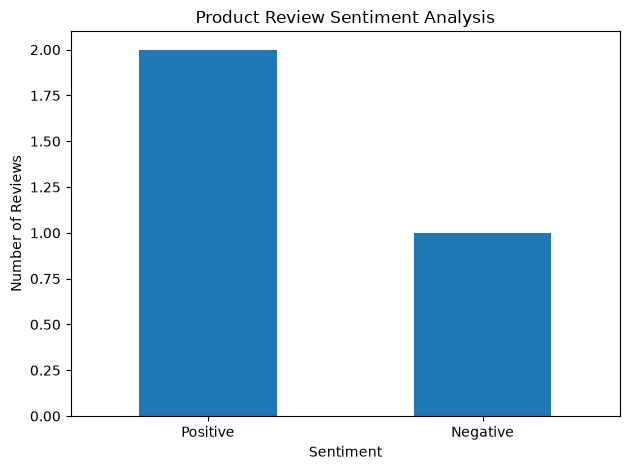

In [115]:

# Step 3: Count and visualize review sentiment

sentiment_counts = reviews["sentiment"].value_counts()

print("Sentiment summary:")
print(sentiment_counts)

sentiment_counts.plot(
    kind="bar",
    title="Product Review Sentiment Analysis",
    xlabel="Sentiment",
    ylabel="Number of Reviews",
    rot=0
)

plt.tight_layout()
plt.show()


In [13]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0049",
    "title": "The refurbished iPhone 14 is working well.",
    "review_text": "The refurbished iPhone 14 J purchased was as advertised. No visible scratches or dents and it works very well. I don’t use it for much more than texting and occasional browsing. I can go the whole day and use only 50% battery. That being said, the only complaint I have is that the battery health was at 85% when I received the phone. Hopefully that doesn’t become an issue otherwise I’m very pleased with the upgrade from my previous iPhone 10.",
    "date": "2025-11-25",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sammy"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 49


In [116]:

# Save sentiment analysis results

csv_path = OUTPUT_DIR / "product_reviews_sentiment.csv"
excel_path = OUTPUT_DIR / "product_reviews_sentiment.xlsx"

reviews.to_csv(csv_path, index=False, encoding="utf-8-sig")
reviews.to_excel(excel_path, index=False)

print("CSV saved:", csv_path.resolve())
print("Excel saved:", excel_path.resolve())


CSV saved: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.csv
Excel saved: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.xlsx


In [14]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0050",
    "title": "Not truly “Excellent” condition",
    "review_text": "purchased this refurbished iPhone listed as “Excellent” condition with only “minor imperfections,” but the device I received was nowhere near that standard. The side paint was peeling and leaving black residue, the battery health was only 86%, and there was a deep dent near the left corner. This goes well beyond minor imperfections, and the overall condition does not reflect what “Excellent” should mean. Very disappointing experience.",
    "date": "2026-05-28",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Abhi"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 50


In [117]:

csv_path = OUTPUT_DIR / "product_reviews_sentiment.csv"
excel_path = OUTPUT_DIR / "product_reviews_sentiment.xlsx"

reviews.to_csv(csv_path, index=False, encoding="utf-8-sig")
reviews.to_excel(excel_path, index=False)

print("CSV saved:", csv_path.resolve())
print("Excel saved:", excel_path.resolve())


CSV saved: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.csv
Excel saved: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.xlsx


In [15]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")
print("Total reviews collected:", len(df))

Total reviews collected: 50


In [118]:

# Step 5: Business insights from reviews

print("TOTAL REVIEWS:", len(reviews))
print("AVERAGE RATING:", round(reviews["rating"].mean(), 2))

print("\nSENTIMENT DISTRIBUTION:")
print(reviews["sentiment"].value_counts())

print("\nAVERAGE RATING BY SENTIMENT:")
print(reviews.groupby("sentiment")["rating"].mean().round(2))

print("\nMOST COMMON REVIEW RATINGS:")
print(reviews["rating"].value_counts().sort_index())


TOTAL REVIEWS: 3
AVERAGE RATING: 3.0

SENTIMENT DISTRIBUTION:
sentiment
Positive    2
Negative    1
Name: count, dtype: int64

AVERAGE RATING BY SENTIMENT:
sentiment
Negative    1.0
Positive    4.0
Name: rating, dtype: float64

MOST COMMON REVIEW RATINGS:
rating
1    1
3    1
5    1
Name: count, dtype: int64


In [16]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

print("Total reviews:", len(df))
print("Unique review IDs:", df["primary_key"].nunique())
print("Missing values:")
print(df.isnull().sum())
print("Duplicate review IDs:", df["primary_key"].duplicated().sum())

Total reviews: 50
Unique review IDs: 50
Missing values:
primary_key      0
title            1
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64
Duplicate review IDs: 0


In [17]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

missing_title = df[df["title"].isna() | (df["title"].astype(str).str.strip() == "")]

display(missing_title)

,primary_key,title,review_text,date,rating,source,reviewer_name
6,BB007,NaN,"Took a long time to arrive, shipped after a w...",2025-07-31,4,Best Buy Canada,Reviewed by Sam


In [18]:
df = pd.read_csv("data/bestbuy_reviews.csv")
print("Missing titles:", df["title"].isna().sum() + (df["title"].astype(str).str.strip() == "").sum())

Missing titles: 1


In [19]:
missing = df["title"].isna() | df["title"].astype(str).str.strip().eq("")
print(df.loc[missing, ["primary_key", "review_text", "rating", "date"]])

  primary_key                                        review_text  rating  \
6       BB007   Took a long time to arrive, shipped after a w...       4   

         date  
6  2025-07-31  


In [20]:
df.loc[missing, "title"] = "Be cautious with 3rd party sellers"
df.to_csv("data/bestbuy_reviews.csv", index=False)

print("Missing titles:", df["title"].isna().sum())

Missing titles: 0


In [21]:

import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load all 50 reviews
df = pd.read_csv("data/bestbuy_reviews.csv")

# Analyze sentiment
analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        sentiment = "Positive"
    elif score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
    return pd.Series([sentiment, score])

df[["sentiment", "sentiment_score"]] = df["review_text"].apply(
    classify_sentiment
)

# Save final output files
df.to_csv("data/bestbuy_reviews_with_sentiment.csv", index=False)
df.to_excel("data/bestbuy_reviews_with_sentiment.xlsx", index=False)

# Display final results
print("Total reviews:", len(df))
print("Unique review IDs:", df["primary_key"].nunique())
print("Missing titles:", df["title"].isna().sum())
print("\nSentiment counts:")
print(df["sentiment"].value_counts())
print("\nAverage star rating:", round(df["rating"].mean(), 2))
print("\nFinal sentiment files saved successfully!")


Total reviews: 50
Unique review IDs: 50
Missing titles: 0

Sentiment counts:
sentiment
Positive    39
Negative    10
Neutral      1
Name: count, dtype: int64

Average star rating: 3.46

Final sentiment files saved successfully!


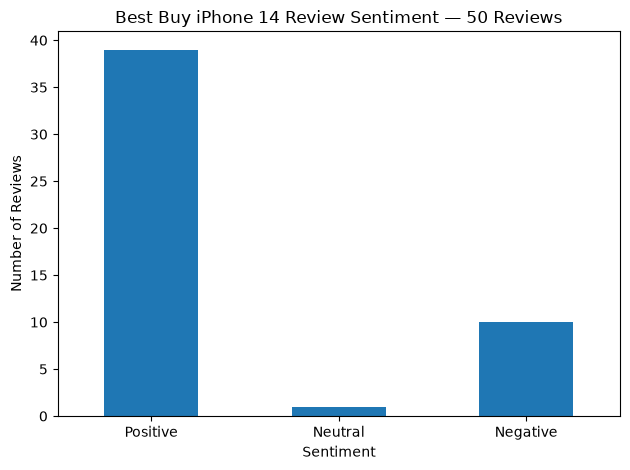

In [22]:
import matplotlib.pyplot as plt

counts = df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
)

counts.plot(kind="bar")
plt.title("Best Buy iPhone 14 Review Sentiment — 50 Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("data/sentiment_chart.png", dpi=150)
plt.show()

In [23]:

from pathlib import Path

# Calculate results from the final 50-review dataset
total = len(df)
counts = df["sentiment"].value_counts()
positive = int(counts.get("Positive", 0))
neutral = int(counts.get("Neutral", 0))
negative = int(counts.get("Negative", 0))
average_rating = df["rating"].mean()

report = f"""# Best Buy Canada Review Sentiment Analysis

## 1. Project Overview
This project analyzes customer reviews for the refurbished
Excellent Apple iPhone 14 128GB Midnight Unlocked on Best Buy Canada.

The goal is to understand customer sentiment using Python and VADER
sentiment analysis.

## 2. Data Collection
- Source: Best Buy Canada product review page
- Product code: 16553704
- Product URL: https://www.bestbuy.ca/en-ca/product/refurbished-excellent-apple-iphone-14-128gb-midnight-unlocked/16553704
- Total reviews analyzed: {total}
- Collection method: Reviews were collected manually from publicly
  available product reviews after automated requests were reset.

## 3. Data Fields
The dataset includes primary key, title, review text, date, rating,
source, and reviewer name. Sentiment results include a sentiment label
and compound score.

## 4. Sentiment Analysis Method
VADER was used to calculate a compound sentiment score for each review:
- Positive: compound score >= 0.05
- Neutral: compound score > -0.05 and < 0.05
- Negative: compound score <= -0.05

## 5. Results
| Sentiment | Number of reviews |
|---|---:|
| Positive | {positive} |
| Neutral | {neutral} |
| Negative | {negative} |
| Total | {total} |

Average star rating: {average_rating:.2f} out of 5.

## 6. Data Quality
- Total records: {total}
- Unique review IDs: {df["primary_key"].nunique()}
- Missing review titles: {df["title"].isna().sum()}
- Missing review text: {df["review_text"].isna().sum()}
- Duplicate review IDs: {df["primary_key"].duplicated().sum()}

## 7. Challenges
Automated requests to the Best Buy Canada website were reset.
Reviews were therefore collected manually from the publicly accessible
product page. This approach took additional time and required checking
the records for completeness and duplicate IDs.

## 8. Limitations
The dataset contains {total} reviews for one product, so it may not
represent all Best Buy customers or products. VADER is a
rule-based sentiment tool and may misinterpret sarcasm, context,
or product-specific language. Sentiment labels reflect review text,
not necessarily the star rating.

## 9. Deliverables
- Notebook: bestbuy_reviews.ipynb
- Original dataset: data/bestbuy_reviews.csv
- Sentiment CSV: data/bestbuy_reviews_with_sentiment.csv
- Sentiment Excel file: data/bestbuy_reviews_with_sentiment.xlsx
- Sentiment chart: data/sentiment_chart.png
- This report: sentiment_analysis_report.md

## 10. Conclusion
The sentiment analysis categorizes the collected customer reviews
into positive, neutral, and negative groups. These results can help
stakeholders understand customer feedback and identify areas that may
need attention.
"""

Path("sentiment_analysis_report.md").write_text(report, encoding="utf-8")
print("Report updated successfully!")
print("Total reviews:", total)
print("Sentiment counts:", positive, "Positive,", neutral, "Neutral,", negative, "Negative")


Report updated successfully!
Total reviews: 50
Sentiment counts: 39 Positive, 1 Neutral, 10 Negative
